# Porto Seguro Safe Driver Prediction – 04 Final Evaluation

**Goal:** estimate how well the final model of notebook 03 works on drivers it has never seen. The model is
refitted on the whole training part and evaluated **once** on the held-out 20% test part, which was not used
for any decision so far (no exploration, no preparation choice, no model selection).

**Final model** (notebook 03, section 11): soft voting of the tuned logistic regression, random forest and
histogram gradient boosting, without the `calc` features. Its 5-fold CV Gini on the training part was 0.274.

**Workflow**
1. Setup: imports and shared project code
2. Load data, split and final configuration
3. Refit the final model on the whole training part
4. Scores on the test part: final model, its three members and the dummy baseline
5. Uncertainty: bootstrap confidence intervals
6. ROC and precision-recall curves
7. Lift and cumulative gains: how well does the model sort the drivers?
8. Decision threshold and confusion matrix
9. Feature importance (permutation importance)
10. Interpretation for the insurer
11. Summary and conclusions

**Run time:** about 20 minutes on a laptop with 8 cores and 16 GB RAM (mostly sections 8 and 9).

## 1. Setup

In [1]:
# 1. Imports, shared project code and settings
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, brier_score_loss,
                             confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import cross_val_predict, train_test_split

# shared project code lives in ../src (same loading, split, preparation, evaluation and models everywhere)
sys.path.insert(0, str(Path.cwd().parent))
from src.data_utils import RANDOM_STATE, feature_groups, load_data, split_features_target, train_test_parts
from src.evaluation import CV_FOLDS, gini_from_auc
from src.models import load_configuration, make_final_model

RESULTS_DIR = Path('../results')
plt.rcParams['figure.dpi'] = 90
FINAL = 'Soft voting (LR + RF + GB)'


def gini(y_true, probability):
    """Normalised Gini coefficient (the competition metric)."""
    return gini_from_auc(roc_auc_score(y_true, probability))

## 2. Load data, split and final configuration

In [2]:
# 2. Load data (-1 recoded as NaN) and the same stratified 80/20 split as in notebooks 01–03
data = load_data()
features, target = split_features_target(data)
X_train, X_test, y_train, y_test = train_test_parts(features, target)
del data, features

all_columns = list(X_train.columns)
for name, part in [('training part', y_train), ('test part', y_test)]:
    print(f"{name}: {len(part):,} rows, {part.sum():,} claims, claim rate {part.mean():.4%}")

training part: 476,169 rows, 17,355 claims, claim rate 3.6447%
test part: 119,043 rows, 4,339 claims, claim rate 3.6449%


In [3]:
# 2. Configuration of the final model and the cross-validation results of notebook 03
configuration = load_configuration()
print(json.dumps(configuration, indent=2))
cv_results = pd.read_csv(RESULTS_DIR / '03_model_comparison_cv.csv', index_col='model')

{
  "final_model": "Soft voting (LR + RF + GB)",
  "drop_calc": true,
  "logistic_regression": {
    "model__C": 0.01
  },
  "random_forest": {
    "max_features": "sqrt",
    "min_samples_leaf": 100
  },
  "gradient_boosting": {
    "model__l2_regularization": 3.1986171822035616,
    "model__learning_rate": 0.026316082737033224,
    "model__max_features": 0.3455361150896956,
    "model__max_leaf_nodes": 10,
    "model__min_samples_leaf": 650
  }
}


## 3. Refit the final model on the whole training part
In notebook 03 every model was trained on 4/5 of the training part (one cross-validation fold was held out).
The final model is now trained once on all 476,169 training rows with the chosen hyperparameters. The
preparation steps (imputation, encoding, scaling) are part of the model, so they are also fitted on the
training part only.

In [4]:
# 3. Fit the soft voting ensemble (logistic regression, random forest, gradient boosting)
final_model = make_final_model(all_columns, configuration)
start = time.time()
final_model.fit(X_train, y_train)
print(f"fitted in {time.time() - start:.0f} s")
print("gradient boosting stopped after",
      final_model.named_estimators_['gradient_boosting'][-1].n_iter_, "trees (early stopping)")

fitted in 172 s
gradient boosting stopped after 545 trees (early stopping)


## 4. Scores on the test part
The voting ensemble keeps its three fitted members, so their test scores come for free: they show whether the
ensemble is better than its parts on new data too. The dummy model predicts the training claim rate for
everyone. Besides Gini and PR-AUC, the **Brier score** (mean squared error of the probabilities, lower is
better) checks the quality of the probabilities themselves, which matter for pricing.

In [5]:
# 4. Predicted claim probabilities on the test part
test_proba = {FINAL: final_model.predict_proba(X_test)[:, 1]}
member_names = {'logistic_regression': 'Logistic regression (tuned C)',
                'random_forest': 'Random forest (tuned)',
                'gradient_boosting': 'Hist. gradient boosting (tuned)'}
for key, name in member_names.items():
    test_proba[name] = final_model.named_estimators_[key].predict_proba(X_test)[:, 1]
test_proba['Dummy (constant claim rate)'] = np.full(len(y_test), y_train.mean())

# 4. Test scores next to the cross-validation estimate of notebook 03
test_scores = pd.DataFrame([{
    'model': name,
    'cv_gini': cv_results.loc[name, 'gini_mean'],
    'test_gini': gini(y_test, proba),
    'test_pr_auc': average_precision_score(y_test, proba),
    'test_brier': brier_score_loss(y_test, proba),
} for name, proba in test_proba.items()]).set_index('model')
test_scores['test_minus_cv'] = test_scores['test_gini'] - test_scores['cv_gini']
print(test_scores.round(4).to_string())
test_scores.to_csv(RESULTS_DIR / '04_test_scores.csv')

                                 cv_gini  test_gini  test_pr_auc  test_brier  test_minus_cv
model                                                                                      
Soft voting (LR + RF + GB)        0.2737     0.2813       0.0676      0.0347         0.0075
Logistic regression (tuned C)     0.2592     0.2669       0.0653      0.0348         0.0076
Random forest (tuned)             0.2704     0.2707       0.0649      0.0348         0.0004
Hist. gradient boosting (tuned)   0.2660     0.2775       0.0669      0.0347         0.0115
Dummy (constant claim rate)       0.0000     0.0000       0.0364      0.0351         0.0000


**Observations:**
- The final model reaches a **test Gini of 0.281** and a test PR-AUC of 0.068. It is the best of all models on the
  test part, as it was in cross-validation.
- All four models score slightly **higher** on the test part than in cross-validation (by +0.000 to +0.012). There
  are two reasons. Each model is now trained on all 476,169 training rows instead of 4/5 of them (gradient
  boosting uses 545 trees, more than inside the folds). And the test part is one random sample with its own
  noise (section 5). So the feared winner's curse does not appear: the CV estimates were not too optimistic.
- The order of the members changed: gradient boosting (0.278) is now ahead of the random forest (0.271). Small
  differences between single models are not stable from one sample to the next. That is a good reason to
  average them.
- The Brier score improves only from 0.0351 (dummy) to 0.0347. With 3.6% claims, most of the squared error comes
  from the randomness of individual claims, which no model can predict. The Gini, which measures the ranking,
  shows the gain much more clearly.

## 5. Uncertainty: bootstrap confidence intervals
The test part has about 4,300 claims, so its Gini is itself an estimate. The **bootstrap** draws 1,000 samples
of the same size with replacement from the test part and recomputes the Gini on each; the 2.5% and 97.5%
quantiles give a 95% confidence interval.

The members are scored on the **same** resamples (paired bootstrap). This answers the question of notebook 03
more precisely: is the ensemble really better than the random forest, or is the difference just noise?

In [6]:
# 5. Paired bootstrap of the test Gini (the same resampled rows for every model)
N_BOOTSTRAP = 1000
compared = [FINAL, 'Random forest (tuned)', 'Hist. gradient boosting (tuned)', 'Logistic regression (tuned C)']
rng = np.random.default_rng(RANDOM_STATE)
y_values = y_test.to_numpy()

bootstrap_rows = []
for _ in range(N_BOOTSTRAP):
    sample = rng.integers(0, len(y_values), len(y_values))
    bootstrap_rows.append({name: gini(y_values[sample], test_proba[name][sample]) for name in compared})
bootstrap = pd.DataFrame(bootstrap_rows)

# 5. 95% intervals of each model's Gini and of the ensemble's advantage over each member
intervals = pd.DataFrame({
    'test_gini': test_scores.loc[compared, 'test_gini'],
    'ci_low': bootstrap.quantile(0.025),
    'ci_high': bootstrap.quantile(0.975),
})
print("Test Gini with 95% bootstrap interval:")
print(intervals.round(4).to_string())

differences = pd.DataFrame({
    'difference': [test_scores.loc[FINAL, 'test_gini'] - test_scores.loc[name, 'test_gini'] for name in compared[1:]],
    'ci_low': [(bootstrap[FINAL] - bootstrap[name]).quantile(0.025) for name in compared[1:]],
    'ci_high': [(bootstrap[FINAL] - bootstrap[name]).quantile(0.975) for name in compared[1:]],
    'share_ensemble_better': [(bootstrap[FINAL] > bootstrap[name]).mean() for name in compared[1:]],
}, index=[f'ensemble - {name}' for name in compared[1:]])
print("\nAdvantage of the ensemble (paired bootstrap):")
print(differences.round(4).to_string())

Test Gini with 95% bootstrap interval:
                                 test_gini  ci_low  ci_high
Soft voting (LR + RF + GB)          0.2813  0.2646   0.2982
Random forest (tuned)               0.2707  0.2543   0.2876
Hist. gradient boosting (tuned)     0.2775  0.2605   0.2946
Logistic regression (tuned C)       0.2669  0.2504   0.2837

Advantage of the ensemble (paired bootstrap):
                                            difference  ci_low  ci_high  share_ensemble_better
ensemble - Random forest (tuned)                0.0105  0.0061   0.0154                  1.000
ensemble - Hist. gradient boosting (tuned)      0.0037 -0.0012   0.0079                  0.941
ensemble - Logistic regression (tuned C)        0.0144  0.0099   0.0193                  1.000


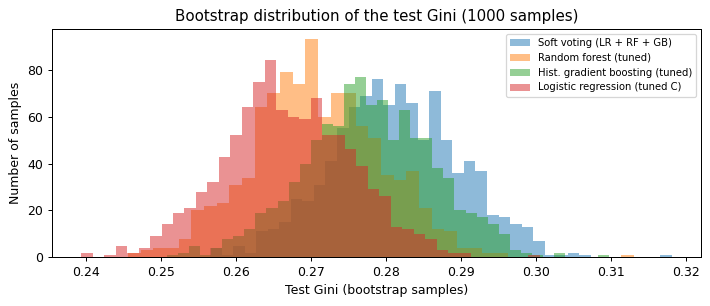

In [7]:
# 5. Bootstrap distributions of the test Gini
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in compared:
    ax.hist(bootstrap[name], bins=40, alpha=0.5, label=name)
ax.set_xlabel('Test Gini (bootstrap samples)')
ax.set_ylabel('Number of samples')
ax.set_title(f'Bootstrap distribution of the test Gini ({N_BOOTSTRAP} samples)')
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(RESULTS_DIR / '04_bootstrap.png', dpi=150)
plt.show()

**Observations:**
- The 95% interval of the final model's test Gini is **0.265 – 0.298**. That is ±0.017, wider than the CV fold
  standard deviation (0.008), because the test part has only 4,339 claims. The CV estimate (0.274) lies inside
  the interval.
- **Paired comparison:** the ensemble is better than the random forest (+0.011, interval 0.006 – 0.015) and the
  logistic regression (+0.014, interval 0.010 – 0.019) in **all** 1,000 resamples. Against gradient boosting
  the advantage (+0.004) is smaller: its interval reaches below 0 (-0.001 – 0.008), and the ensemble wins in 94%
  of the resamples.
- The pairing matters. The single intervals in the histogram overlap a lot, but on the *same* drivers the
  ensemble is almost always ahead. This confirms the choice of notebook 03 with data that played no part in it.

## 6. ROC and precision-recall curves
The ROC curve shows the share of claims found (true positive rate) against the share of non-claims wrongly
flagged (false positive rate) for every threshold; Gini = 2·AUC − 1. The precision-recall curve focuses on the
rare class: which share of the flagged drivers really claims (precision) for a given share of claims found
(recall). A random model has a precision equal to the claim rate (3.6%) at every recall.

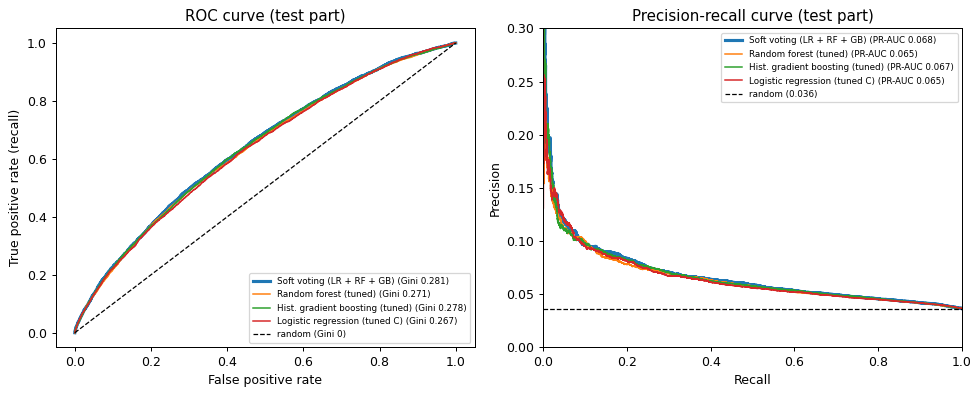

In [8]:
# 6. ROC curve (left) and precision-recall curve (right) of the final model and its members
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
for name in compared:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, test_proba[name])
    precision, recall, _ = precision_recall_curve(y_test, test_proba[name])
    width = 2.5 if name == FINAL else 1.2
    ax_roc.plot(false_positive_rate, true_positive_rate, linewidth=width,
                label=f"{name} (Gini {test_scores.loc[name, 'test_gini']:.3f})")
    ax_pr.plot(recall, precision, linewidth=width,
               label=f"{name} (PR-AUC {test_scores.loc[name, 'test_pr_auc']:.3f})")
ax_roc.plot([0, 1], [0, 1], 'k--', linewidth=1, label='random (Gini 0)')
ax_pr.axhline(y_test.mean(), color='k', linestyle='--', linewidth=1, label=f'random ({y_test.mean():.3f})')
ax_roc.set(xlabel='False positive rate', ylabel='True positive rate (recall)', title='ROC curve (test part)')
ax_pr.set(xlabel='Recall', ylabel='Precision', title='Precision-recall curve (test part)', xlim=(0, 1), ylim=(0, 0.3))
ax_roc.legend(fontsize=7, loc='lower right')
ax_pr.legend(fontsize=7, loc='upper right')
plt.tight_layout()
fig.savefig(RESULTS_DIR / '04_roc_pr.png', dpi=150)
plt.show()

**Observations:**
- The ROC curves of the four models lie almost on top of each other, clearly above the diagonal. There is no
  threshold region where one model is much better than another.
- Precision is highest for the very few drivers with the highest scores (above 20% at almost zero recall) and
  falls quickly. At a recall of 20% it is about 8%, about twice the claim rate. At a recall of 60% it is only
  about 5%.
- So the model cannot *identify* individual claimants. It can only shift the odds. That is typical for
  insurance data, where most claims are accidents that no driver attribute predicts.

## 7. Lift and cumulative gains
For an insurer the ranking is what matters: the drivers are sorted by predicted risk and split into 10 groups
of equal size (deciles, decile 1 = the 10% riskiest). For each decile:
- the observed claim rate and the **lift** (claim rate divided by the average claim rate);
- the mean predicted probability: if it matches the observed rate, the probabilities are **calibrated** and can
  be used directly for pricing;
- the cumulative share of all claims found when the riskiest deciles are checked first (**cumulative gains**).

In [9]:
# 7. Lift table of the final model on the test part
final_proba = test_proba[FINAL]
risk_rank = pd.Series(final_proba).rank(method='first', ascending=False)
lift_data = pd.DataFrame({'probability': final_proba, 'claim': y_values,
                          'decile': pd.qcut(risk_rank, 10, labels=range(1, 11))})
lift_table = lift_data.groupby('decile', observed=True).agg(
    drivers=('claim', 'size'), claims=('claim', 'sum'),
    claim_rate=('claim', 'mean'), mean_predicted=('probability', 'mean'))
lift_table['lift'] = lift_table['claim_rate'] / y_values.mean()
lift_table['cumulative_share_of_claims'] = lift_table['claims'].cumsum() / lift_table['claims'].sum()
print(lift_table.round(4).to_string())
lift_table.to_csv(RESULTS_DIR / '04_lift_table.csv')

        drivers  claims  claim_rate  mean_predicted    lift  cumulative_share_of_claims
decile                                                                                 
1         11905     960      0.0806          0.0748  2.2124                      0.2212
2         11904     616      0.0517          0.0518  1.4197                      0.3632
3         11904     545      0.0458          0.0437  1.2561                      0.4888
4         11904     437      0.0367          0.0384  1.0072                      0.5895
5         11905     409      0.0344          0.0345  0.9426                      0.6838
6         11904     368      0.0309          0.0310  0.8481                      0.7686
7         11904     333      0.0280          0.0279  0.7675                      0.8454
8         11904     282      0.0237          0.0248  0.6499                      0.9103
9         11904     233      0.0196          0.0214  0.5370                      0.9640
10        11905     156      0.0

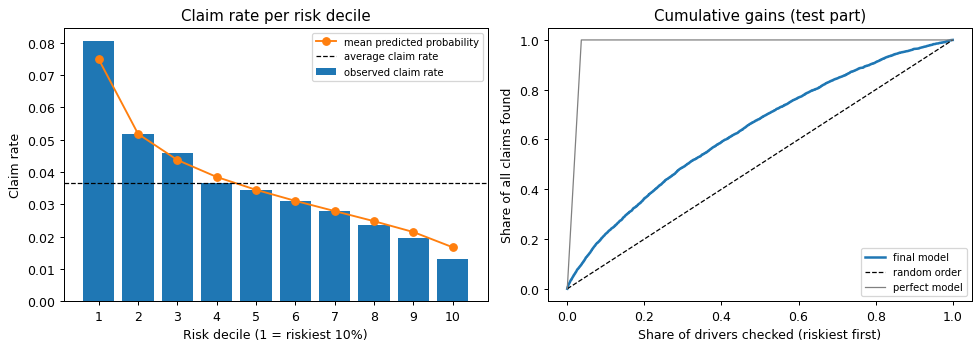

In [10]:
# 7. Claim rate per decile (left) and cumulative gains curve (right)
fig, (ax_lift, ax_gain) = plt.subplots(1, 2, figsize=(11, 4))
deciles = lift_table.index.astype(int)
ax_lift.bar(deciles, lift_table['claim_rate'], color='tab:blue', label='observed claim rate')
ax_lift.plot(deciles, lift_table['mean_predicted'], 'o-', color='tab:orange', label='mean predicted probability')
ax_lift.axhline(y_values.mean(), color='k', linestyle='--', linewidth=1, label='average claim rate')
ax_lift.set(xlabel='Risk decile (1 = riskiest 10%)', ylabel='Claim rate', title='Claim rate per risk decile',
            xticks=deciles)
ax_lift.legend(fontsize=8)

share_of_drivers = np.arange(1, len(y_values) + 1) / len(y_values)
sorted_claims = y_values[np.argsort(-final_proba, kind='stable')]
ax_gain.plot(share_of_drivers, np.cumsum(sorted_claims) / sorted_claims.sum(), linewidth=2, label='final model')
ax_gain.plot([0, 1], [0, 1], 'k--', linewidth=1, label='random order')
ax_gain.plot([0, y_values.mean(), 1], [0, 1, 1], color='grey', linewidth=1, label='perfect model')
ax_gain.set(xlabel='Share of drivers checked (riskiest first)', ylabel='Share of all claims found',
            title='Cumulative gains (test part)')
ax_gain.legend(fontsize=8, loc='lower right')
plt.tight_layout()
fig.savefig(RESULTS_DIR / '04_lift_gains.png', dpi=150)
plt.show()

**Observations:**
- The claim rate falls steadily from decile 1 to decile 10: **8.1%** among the 10% riskiest drivers and **1.3%**
  among the 10% safest. That is a factor of 6.2, and a lift of 2.2 for the top decile.
- **Calibration:** the mean predicted probability matches the observed claim rate in every decile within
  0.6 percentage points, so the probabilities can be read directly as claim frequencies. At the extremes the
  predictions are slightly compressed toward the average (decile 1: 7.5% predicted vs 8.1% observed; decile 10:
  1.7% vs 1.3%). This is a known effect of averaging several models.
- **Cumulative gains:** the riskiest 10% of drivers account for 22% of all claims, the riskiest 30% for 49% and the
  riskiest half for 68%. The curve lies well above random order but far below the perfect model. This
  matches a Gini of 0.28: the Gini is the area between the model curve and the diagonal, relative to the
  perfect model.

## 8. Decision threshold and confusion matrix
To turn probabilities into decisions (e.g. "review this policy"), a threshold is needed. It must **not** be
chosen on the test part, otherwise the test scores would be optimistic again. It is chosen on **out-of-fold
predictions** of the training part: each training row is predicted by a model fitted on the other 4 folds
(the same 5 folds as in notebooks 02–03), which imitates new data.

Three thresholds are compared:
- **0.5**, the default of `predict()`;
- the threshold with the **highest F1 score** (balance of precision and recall) on the out-of-fold predictions;
- a business rule: **flag the 10% riskiest drivers** (the 90% quantile of the out-of-fold probabilities).

In [11]:
# 8. Out-of-fold probabilities of the final model on the training part (5 refits, folds one after the other)
start = time.time()
oof_proba = cross_val_predict(make_final_model(all_columns, configuration), X_train, y_train,
                              cv=CV_FOLDS, method='predict_proba', n_jobs=1)[:, 1]
print(f"out-of-fold predictions in {time.time() - start:.0f} s, out-of-fold Gini {gini(y_train, oof_proba):.4f}")

# 8. Thresholds chosen on the training part only
precision, recall, pr_thresholds = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
thresholds = {
    'default 0.5': 0.5,
    'max F1 (out-of-fold)': pr_thresholds[f1_scores.argmax()],
    'top 10% (out-of-fold)': np.quantile(oof_proba, 0.9),
}
for name, threshold in thresholds.items():
    print(f"{name:24s} threshold = {threshold:.4f}")

out-of-fold predictions in 518 s, out-of-fold Gini 0.2737


default 0.5              threshold = 0.5000
max F1 (out-of-fold)     threshold = 0.0582
top 10% (out-of-fold)    threshold = 0.0575


In [12]:
# 8. The thresholds applied to the test part
def threshold_report(y_true, probability, threshold):
    """Confusion matrix counts and the usual scores when every probability >= threshold is flagged."""
    flagged = probability >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, flagged, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn)
    return {'threshold': threshold, 'share_flagged': flagged.mean(), 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'accuracy': (tp + tn) / len(y_true), 'precision': precision, 'recall': recall,
            'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0}

threshold_table = pd.DataFrame({name: threshold_report(y_values, final_proba, threshold)
                                for name, threshold in thresholds.items()}).T
print(threshold_table.round(4).to_string())
print(f"\naccuracy of always predicting 'no claim': {1 - y_values.mean():.4f}")
threshold_table.to_csv(RESULTS_DIR / '04_thresholds.csv')

                       threshold  share_flagged     TP       FP      FN        TN  accuracy  precision  recall      f1
default 0.5               0.5000         0.0000    0.0      0.0  4339.0  114704.0    0.9636     0.0000  0.0000  0.0000
max F1 (out-of-fold)      0.0582         0.0982  948.0  10742.0  3391.0  103962.0    0.8813     0.0811  0.2185  0.1183
top 10% (out-of-fold)     0.0575         0.1028  976.0  11265.0  3363.0  103439.0    0.8771     0.0797  0.2249  0.1177

accuracy of always predicting 'no claim': 0.9636


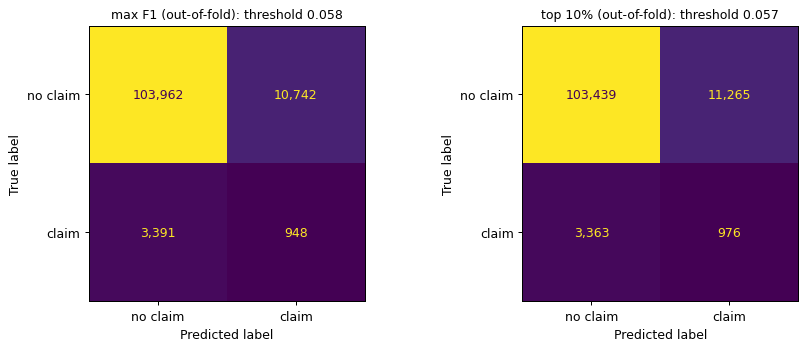

In [13]:
# 8. Confusion matrices on the test part for the two useful thresholds
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ['max F1 (out-of-fold)', 'top 10% (out-of-fold)']):
    flagged = (final_proba >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_values, flagged, display_labels=['no claim', 'claim'],
                                            values_format=',d', colorbar=False, ax=ax)
    ax.set_title(f'{name}: threshold {thresholds[name]:.3f}', fontsize=10)
plt.tight_layout()
plt.show()

**Observations:**
- **Threshold 0.5 flags nobody.** No driver has a predicted claim probability of 50%. The accuracy (96.36%) is
  exactly that of always predicting "no claim". This is why accuracy is useless here and why the project uses
  Gini and PR-AUC.
- The F1-optimal threshold (0.058, about 1.6 times the average claim rate) and the top-10% rule (0.0575) are
  almost the same. Both were chosen on the training part and transfer well: the top-10% threshold flags 10.3% of
  the test drivers.
- At the top-10% threshold the model finds 976 of 4,339 claims (recall 22%). Precision is 8.0%, 2.2 times the
  claim rate, so each correctly flagged claimant comes with almost 12 false alarms. The best F1 is only 0.12.
- For a yes/no decision on single drivers the model is therefore weak. Its value lies in the **ranking and the
  probabilities**, which is how an insurer uses it (section 10).

## 9. Feature importance (permutation importance)
The ensemble has no single list of weights. **Permutation importance** works for any model: the values of one
feature are shuffled across the drivers, which breaks its link with the target, and the drop in Gini is
measured. A large drop means the model relies on that feature. It is computed on a stratified sample of 40,000
test rows (3 shuffles per feature) to keep the run time reasonable; the dropped `calc` features are skipped.

In [14]:
# 9. Permutation importance of the 37 used features on a stratified sample of the test part
X_sample, _, y_sample, _ = train_test_split(X_test, y_test, train_size=40000, stratify=y_test,
                                            random_state=RANDOM_STATE)
calc_columns = set(feature_groups(all_columns)['calc']) if configuration['drop_calc'] else set()
used_columns = [column for column in all_columns if column not in calc_columns]
N_REPEATS = 3

start = time.time()
baseline_gini = gini(y_sample, final_model.predict_proba(X_sample)[:, 1])
importance_rows = []
for column in used_columns:
    drops = []
    for _ in range(N_REPEATS):
        shuffled = X_sample.copy()
        shuffled[column] = rng.permutation(shuffled[column].to_numpy())
        drops.append(baseline_gini - gini(y_sample, final_model.predict_proba(shuffled)[:, 1]))
    importance_rows.append({'feature': column, 'gini_drop': np.mean(drops), 'gini_drop_std': np.std(drops)})
importance = pd.DataFrame(importance_rows).set_index('feature').sort_values('gini_drop', ascending=False)
importance['group'] = importance.index.str.split('_').str[1]
print(f"computed in {time.time() - start:.0f} s; Gini of the sample before shuffling: {baseline_gini:.4f}")
print(importance.head(15).round(4).to_string())
importance.to_csv(RESULTS_DIR / '04_permutation_importance.csv')

computed in 315 s; Gini of the sample before shuffling: 0.2636
               gini_drop  gini_drop_std group
feature                                      
ps_ind_05_cat     0.0273         0.0035   ind
ps_car_13         0.0220         0.0059   car
ps_car_01_cat     0.0113         0.0003   car
ps_ind_06_bin     0.0109         0.0009   ind
ps_reg_03         0.0084         0.0018   reg
ps_ind_03         0.0083         0.0016   ind
ps_reg_01         0.0070         0.0012   reg
ps_car_11_cat     0.0052         0.0023   car
ps_ind_15         0.0048         0.0025   ind
ps_ind_09_bin     0.0046         0.0013   ind
ps_car_03_cat     0.0042         0.0009   car
ps_ind_17_bin     0.0041         0.0038   ind
ps_ind_16_bin     0.0039         0.0005   ind
ps_reg_02         0.0039         0.0023   reg
ps_car_07_cat     0.0035         0.0015   car


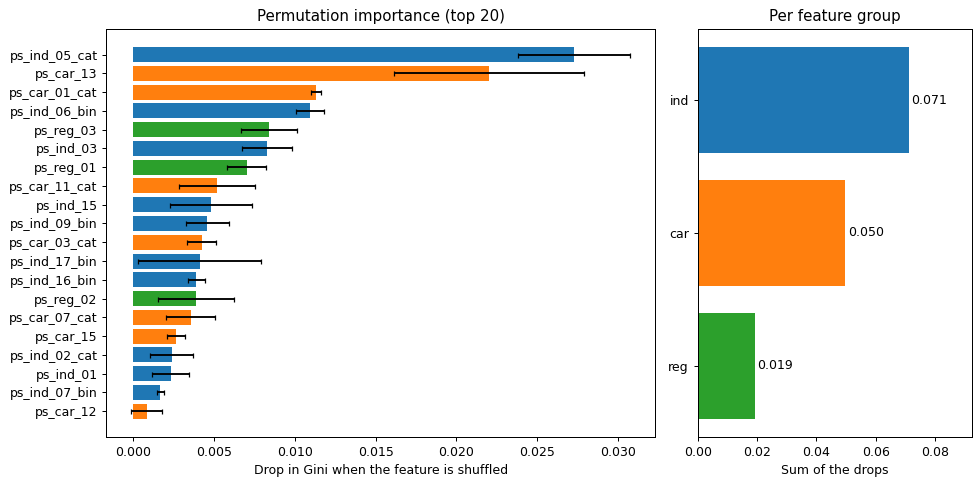

In [15]:
# 9. The 20 most important features (left) and the total importance per feature group (right)
fig, (ax_feature, ax_group) = plt.subplots(1, 2, figsize=(11, 5.5), gridspec_kw={'width_ratios': [2, 1]})
top = importance.head(20).iloc[::-1]
colors = top['group'].map({'ind': 'tab:blue', 'reg': 'tab:green', 'car': 'tab:orange'})
ax_feature.barh(top.index, top['gini_drop'], xerr=top['gini_drop_std'], color=colors, capsize=2)
ax_feature.set(xlabel='Drop in Gini when the feature is shuffled', title='Permutation importance (top 20)')

group_importance = importance.groupby('group')['gini_drop'].sum().sort_values()
bars = ax_group.barh(group_importance.index, group_importance.values,
                     color=group_importance.index.map({'ind': 'tab:blue', 'reg': 'tab:green', 'car': 'tab:orange'}))
ax_group.bar_label(bars, fmt='%.3f', padding=2)
ax_group.set(xlabel='Sum of the drops', title='Per feature group', xlim=(0, group_importance.max() * 1.3))
plt.tight_layout()
fig.savefig(RESULTS_DIR / '04_permutation_importance.png', dpi=150)
plt.show()

**Observations:**
- The two most important features are `ps_ind_05_cat` (Gini drop 0.027) and `ps_car_13` (0.022). `ps_car_13` was
  also the strongest single feature in the EDA (univariate Gini 0.15).
- `ps_car_01_cat` is third. In the EDA its signal came from its 84 missing values with a 30% claim rate, so keeping
  "missing" as information (notebook 02) pays off. `ps_ind_06_bin` follows, one of the hidden one-hot groups
  found in the EDA.
- By group, the driver features (`ind`, 18 features) contribute most in total, then the car features (`car`,
  16). The three region features (`reg`) contribute the most per feature.
- The near-constant features from the EDA (`ps_ind_10_bin` – `ps_ind_13_bin`, `ps_ind_14`, `ps_car_10_cat`) have
  an importance of about zero. A few features (e.g. `ps_car_11`, `ps_car_14`, `ps_car_04_cat`) are even slightly
  negative, within the noise. Their information is either absent or already contained in correlated features
  (e.g. `ps_car_12`–`ps_car_15`).
- Caveat: shuffling one feature of a correlated group underestimates its importance, because the model can partly
  recover the information from the others. The features are anonymized, so their real meaning is unknown.

## 10. Interpretation for the insurer

**What the model is good for.** The model is a **risk score**, not a yes/no classifier. It sorts the drivers by
their probability of a claim. Its probabilities are calibrated, so they can be used as expected claim frequencies.

- **Pricing:** the riskiest 10% of drivers claim 6 times as often as the safest 10% (8.1% vs 1.3%). If the
  frequency part of the premium is proportional to the predicted probability, the top decile would pay about
  2.2 times and the bottom decile about 0.4 times the average. This is the goal of the competition: lower prices
  for safe drivers, higher prices for risky drivers.
- **Targeting:** checking the 30% riskiest policies (e.g. for telematics offers or a manual review) reaches about
  half of all future claims.

**Limits.**
- The model predicts *whether* a claim happens, not *how much* it costs. The data has no claim amounts, and a
  premium needs both.
- Even the best ranking leaves most of the risk unexplained: 92% of the drivers in the riskiest decile do not
  claim. Individual decisions (e.g. refusing a customer) cannot be justified by this model alone.
- The features are anonymized. Before use, the insurer would have to check that no feature is a proxy for
  attributes that may not be used for pricing (fairness and legal requirements).
- The data covers one period. The model should be monitored and refitted when driver behaviour or the
  portfolio changes.

## 11. Summary and conclusions

| Result on the held-out test part (119,043 drivers, 4,339 claims) | Value |
|---|---|
| Test Gini of the final model (soft voting LR + RF + GB) | **0.281** (95% CI 0.265 – 0.298) |
| Cross-validation estimate from notebook 03 | 0.274 (inside the interval) |
| Advantage over the best single member on the same drivers | +0.004 to +0.014; significant against RF and LR |
| Test PR-AUC (random: 0.036) | 0.068 |
| Claim rate riskiest vs safest 10% | 8.1% vs 1.3% (factor 6.2) |
| Claims among the riskiest 30% of drivers | 49% |
| Precision / recall when flagging the riskiest 10% | 8.0% / 22% |

**Conclusions**
1. The final model generalizes: its test Gini is in line with the cross-validation estimate, so the evaluation
   protocol (pipelines inside CV, one untouched test part) worked as intended.
2. The ensemble is the right choice. On new data it is at least as good as each member and clearly better than
   two of them.
3. Claims are hard to predict for one driver (best F1 0.12) but easy to *rank* at the portfolio level. The model
   is useful for risk-based pricing, which is the competition's purpose.
4. The project followed CRISP-DM from data understanding to evaluation. Each decision (dropping `calc`, model
   choice, threshold) was made on the training part only.

**Comparison with the competition.** The winning Kaggle solutions reached a Gini of about 0.297 on Kaggle's
private test set. Our interval (0.265 – 0.298) reaches that region, but the two numbers come from different data.
A fair comparison needs a submission on Kaggle's own test set. This is done in notebook 05 as an extra, after
the final model was fixed. Kaggle's score is never used to change the model.